# 02 · Cleaning COCO val2017 → manifest

**This notebook explains and visually checks the cleaning.** The rules themselves live in `src/clean.py`, and
`python -m src.clean` produces the identical outputs without the notebook.

**Input:** the 5,000 val2017 images + `captions_val2017.json` (verified in `01_data_integrity_check`).
**Output** (in `manifests/`, no image files are deleted, moved, or modified):
- `manifest.json`: kept images and their unique captions
- `drop_log.csv`: every dropped image with the rule and the measured value
- `cleaning_summary.json`: counts at each stage + the config used

| Rule | Decision |
|---|---|
| Grayscale | **Drop.** Single-channel files *and* B&W photos stored as RGB |
| Extreme aspect ratio | **Drop** if long/short side > **2.0** (center crop would keep < 50 % of the image) |
| Zero-object images | **Keep.** Captions are still valid |
| Duplicate captions | **Remove** within an image (ignoring case/punctuation). Keep all unique ones |
| Crop / resize | Center-crop square → 512×512 (bicubic). Applied **at load time** by `src/data.py` |

Prompt selection (one caption per image) is experiment design, so it is **not** done here. See `03_text_embeddings`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import random
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from src import clean
from src.data import IMG_DIR, MANIFEST_DIR, center_crop_resize, load_manifest

print("config:", clean.CONFIG)
images, raw_caps = clean.load_coco_captions()
print(f"{len(images):,} images, {sum(len(v) for v in raw_caps.values()):,} captions")

config: {'aspect_ratio_max': 2.0, 'gray_chroma_p99_max': 15, 'gray_check_size': 128}
5,000 images, 25,014 captions


## Rule 1 · Grayscale
Two kinds:
1. **Single-channel files** (PIL mode `L`): flagged directly.
2. **B&W photos saved as RGB**: the three channels are (nearly) equal at every pixel. For each pixel take
   `max(R,G,B) − min(R,G,B)` (its "chroma"). If even the 99th-percentile pixel has chroma < 15, the image has
   essentially no color anywhere.

**Why the 99th percentile and not the mean:** a snowy scene with one small red flag has a low *mean* chroma but
a high p99, so it is correctly kept.

**Known limitation (checked by eye):** the boundary is fuzzy in both directions, and no single threshold separates it cleanly.
- Just **above** 15 (kept): a few *toned* B&W prints (sepia or scanner tint), whose uniform tint reads as color.
- Just **below** 15 (dropped): a few color photos with almost no color in them (overcast sky, gray water).

A tint-invariant measure (spread of Cb/Cr around the image's median) was tested and overlapped just as much,
because muted color and toned B&W are genuinely similar. The ambiguous zone is about 20–30 images (< 1 % of the data), and
these images are nearly colorless either way, so the effect on FID is negligible. Recorded here rather than hand-labeled.

In [2]:
gray_drops, chroma = clean.find_grayscale(images)
reasons = [r for v in gray_drops.values() for r, _ in v]
print({r: reasons.count(r) for r in set(reasons)})

v = np.array([c for c in chroma.values() if c is not None])
print("sensitivity (RGB images with p99 chroma below t):",
      {t: int((v < t).sum()) for t in (5, 10, 15, 20, 30, 40)})

{'grayscale_rgb_encoded': 155, 'grayscale_single_channel': 10}
sensitivity (RGB images with p99 chroma below t): {5: 129, 10: 142, 15: 155, 20: 172, 30: 234, 40: 336}


**Visual check:** top row = random sample of dropped images. Bottom row = *kept* images closest to the cutoff (the least colorful that still passed). Expect a few toned B&W prints here (see the limitation above).

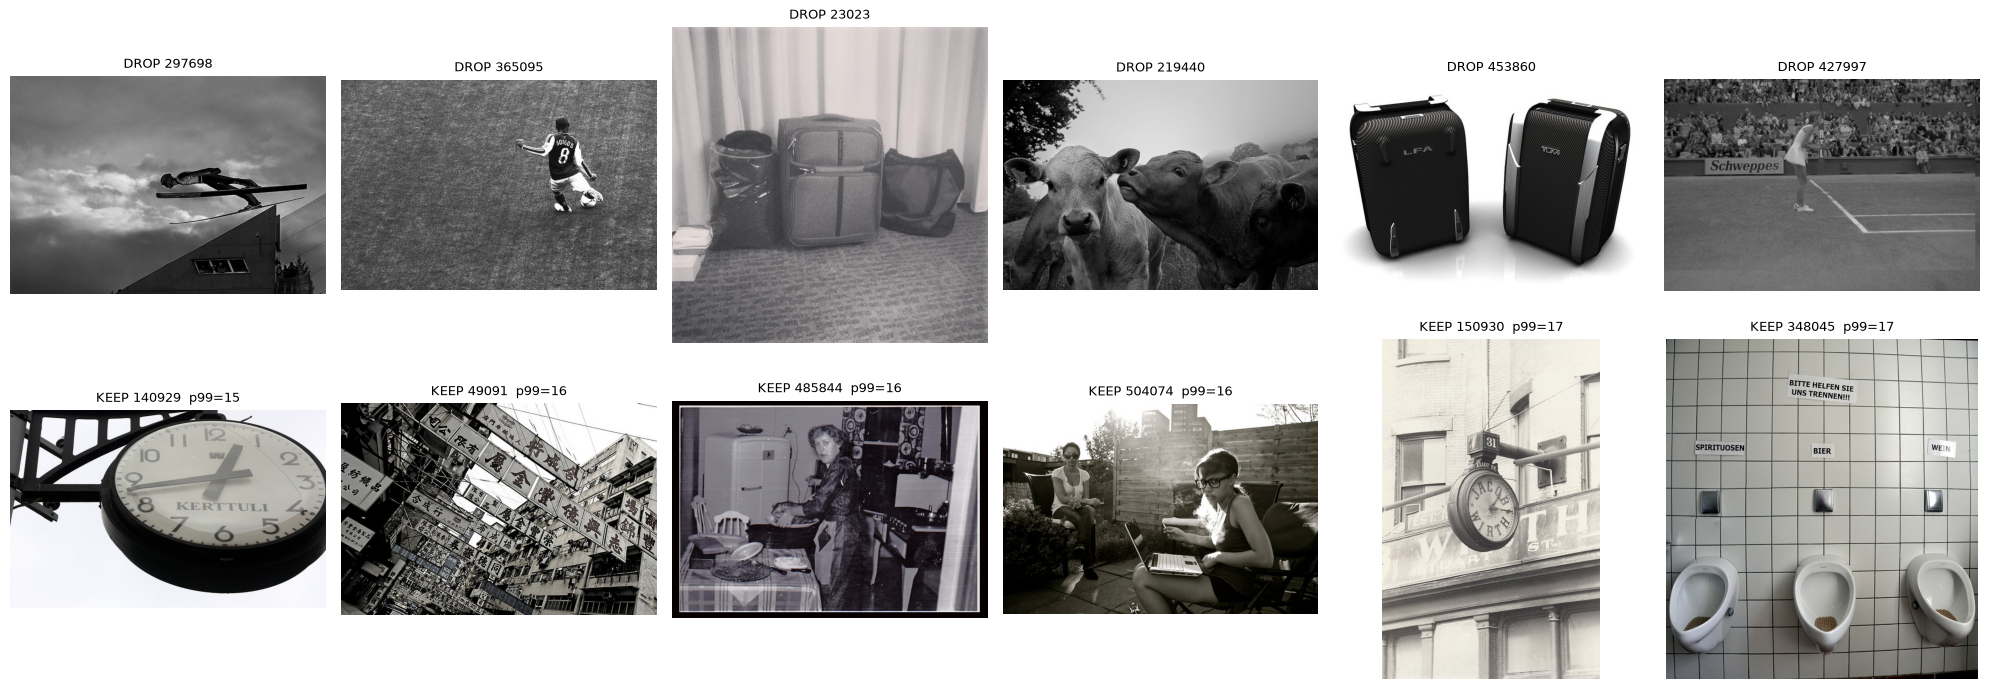

In [3]:
thr = clean.CONFIG["gray_chroma_p99_max"]
dropped_s = random.Random(0).sample(sorted(gray_drops), 6)
borderline = sorted((c, i) for i, c in chroma.items() if c is not None and c >= thr)[:6]

fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for ax, i in zip(axes[0], dropped_s):
    ax.imshow(Image.open(IMG_DIR / images[i]["file_name"]).convert("RGB")); ax.set_title(f"DROP {i}", fontsize=9); ax.axis("off")
for ax, (c, i) in zip(axes[1], borderline):
    ax.imshow(Image.open(IMG_DIR / images[i]["file_name"])); ax.set_title(f"KEEP {i}  p99={c:.0f}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## Rule 2 · Extreme aspect ratio
`ratio = long side / short side`. A center crop to a square keeps `1 / ratio` of the long side, so at the
2.0 cutoff the crop keeps at least half the image. 2.0 is roughly the 99th percentile. Above it the distribution
is a thin tail of panoramas and tall shots. The cutoff will be revisited with a CLIP full-vs-crop alignment check in
the embedding notebook.

In [4]:
wide_drops, ratio = clean.find_extreme_aspect(images)
r = np.array(list(ratio.values()))
print(f"dropped (ratio > {clean.CONFIG['aspect_ratio_max']}): {len(wide_drops)}")
print("sensitivity:", {t: int((r > t).sum()) for t in (1.5, 1.78, 2.0, 2.5)})
print(f"of those, also grayscale: {len(set(wide_drops) & set(gray_drops))}")

dropped (ratio > 2.0): 53
sensitivity: {1.5: 1162, 1.78: 125, 2.0: 53, 2.5: 16}
of those, also grayscale: 3


**Visual check:** the kept images **just under** the cutoff (the worst crops we still keep), using the real
load-time transform from `src/data.py`. The red box marks the area the crop keeps. Some of these already lose
caption content (e.g. part of a plane, plates mentioned in the caption), which is why the CLIP check is worth doing.

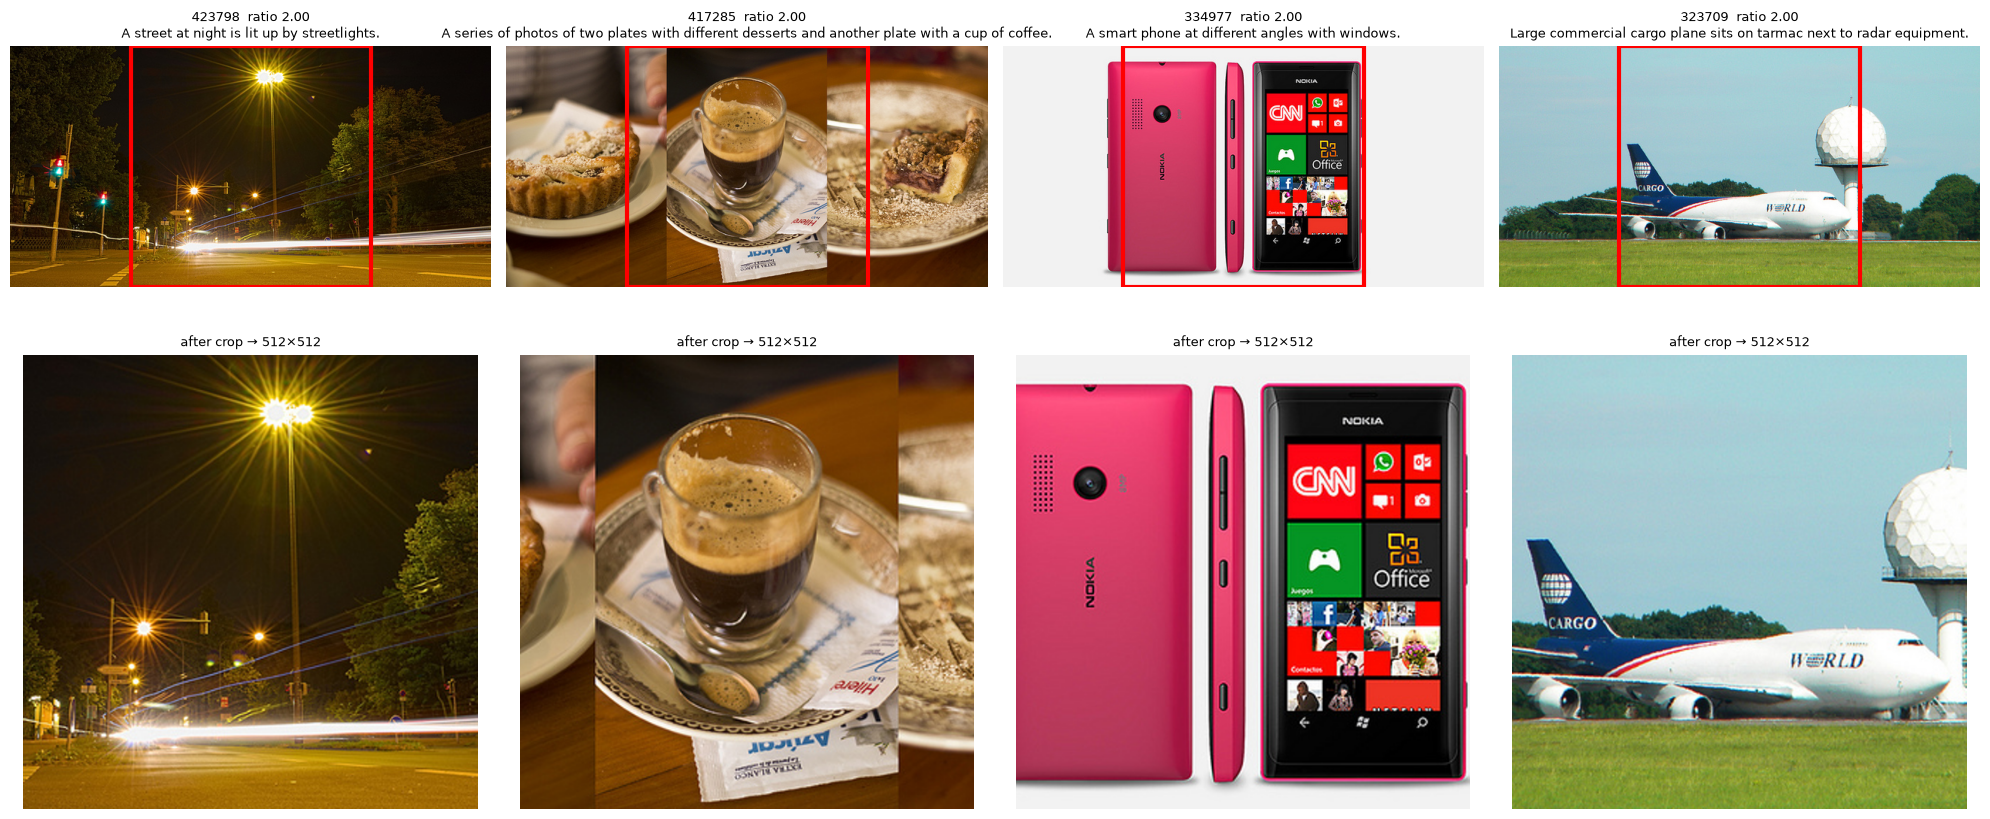

In [5]:
drops = clean.merge_drops(gray_drops, wide_drops)
worst_kept = sorted(((rv, i) for i, rv in ratio.items()
                     if rv <= clean.CONFIG["aspect_ratio_max"] and i not in drops), reverse=True)[:4]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for col, (rv, i) in enumerate(worst_kept):
    img = Image.open(IMG_DIR / images[i]["file_name"])
    w, h = img.size; s = min(w, h); l, t = (w - s) // 2, (h - s) // 2
    axes[0, col].imshow(img); axes[0, col].add_patch(plt.Rectangle((l, t), s, s, fill=False, ec="red", lw=3))
    axes[0, col].set_title(f"{i}  ratio {rv:.2f}\n{raw_caps[i][0]}", fontsize=9); axes[0, col].axis("off")
    axes[1, col].imshow(center_crop_resize(img)); axes[1, col].set_title("after crop → 512×512", fontsize=9); axes[1, col].axis("off")
plt.tight_layout(); plt.show()

## Captions · dedupe + write outputs
Two captions count as duplicates if they match after lower-casing, removing punctuation, and collapsing whitespace.
The first occurrence's original text is kept.

In [6]:
manifest, summary = clean.build(images, raw_caps, drops)
clean.write_outputs(manifest, summary, drops, images)

for s in summary["stages"]:
    print(f"{s['stage']:<22} {s['images']:>5,} images" + (f"   {s['captions']:>6,} captions" if "captions" in s else ""))
print("\ndropped by reason:", summary["dropped_by_reason"], f"(total images dropped: {summary['dropped_images_total']})")
print("duplicate captions removed:", summary["duplicate_captions_removed"])
print("unique captions per image -> #images:", summary["unique_captions_per_image"])

start                  5,000 images   25,014 captions
after grayscale        4,835 images
after aspect ratio     4,785 images
after caption dedupe   4,785 images   23,925 captions

dropped by reason: {'grayscale_rgb_encoded': 155, 'aspect_ratio': 53, 'grayscale_single_channel': 10} (total images dropped: 215)
duplicate captions removed: 13
unique captions per image -> #images: {'3': 2, '4': 7, '5': 4766, '6': 9, '7': 1}


## Re-load check
Read the manifest back the way every later notebook will (`src.data.load_manifest`) and confirm it's self-consistent.

In [7]:
m = load_manifest()
ids = [e["image_id"] for e in m["images"]]
assert len(ids) == len(set(ids)) == m["n_images"]
assert all((IMG_DIR / e["file_name"]).exists() for e in m["images"])
assert all(len(e["captions"]) >= 3 for e in m["images"])
assert not set(ids) & set(drops)
print(f"manifest OK: {m['n_images']:,} images, {m['n_captions']:,} captions")

manifest OK: 4,785 images, 23,925 captions
